# Dar_049 - Radiation: calendar support, upper tails and solar associations

## Questions
- What do month, quarter, four-month, half-year, year, two-year and calendar-season summaries hide or reveal?
- How do daily maxima differ from daily/monthly medians, accounting for actual quality support?
- Do consecutive observed upper-tail days cluster, without calling them physical events or durations?
- Does a solar association persist within years or for consecutive-day changes, rather than only pooled levels?
- Are the earlier monthly medians preserved, and what is still missing for an operational radiation decision?

Reuses all accepted radiation daily series and their quality/provenance rather than rereading 94 million records. Platform, sensor, energy and version remain separate. The earlier sparse primary-event cohort is **not expanded**. GOES is Earth-orbit space-weather context, never lunar-local exposure or Earth-climate substitution. Orbital counts/flux are not shielded crew dose.

In [1]:
from pathlib import Path
import sys,json
import pandas as pd
from IPython.display import display,Image
root=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'darrel stuff/EDA').is_dir())
sys.path.insert(0,str(root/'darrel stuff/EDA/Moon/Stage3_Requirements'))
from stage3_radiation_time_eda import execute

## Execute the study
Accepted completed inputs are hash checked. This adds new tail-segment and trend-sensitivity analyses; it is not just a renamed extract of earlier tables.

In [2]:
folder,findings=execute(sample=False)
display(findings)

Prior monthly columns: series_id,period,year,period_kind,period_start_utc,period_stop_exclusive_utc,expected_calendar_days,recorded_days,valid_days,valid_day_fraction,recorded_samples,valid_samples,valid_seconds,valid_time_fraction,median_of_daily_medians,p95_of_daily_medians,maximum_observed_value,maximum_daily_p95,comparison_scope,observed_level_order_within_year,comparable_nonempty_periods,coverage_note


{
  "subject": "radiation",
  "sample": false,
  "series": 79,
  "daily_rows": 35281,
  "first_utc": "2023-07-01 00:00:00+00:00",
  "last_utc": "2026-10-31 00:00:00+00:00",
  "tables": {
    "daily_context": 35281,
    "series_catalog": 79,
    "calendar_context": 3152,
    "matched_June_October_years": 108,
    "descriptive_upper_tail_thresholds": 79,
    "observed_upper_tail_segments": 138,
    "solar_associations": 212,
    "paired_solar_daily_values": 19459,
    "previous_monthly_context": 1232,
    "stage4_radiation_proposals": 5,
    "crosscheck_Dar043": 1232
  },
  "crater_solar_descriptive_checks": [
    {
      "series_id": "RAD_CRATER_SEC_selected_state",
      "comparison_window": "all_common_dates",
      "paired_valid_dates": 1050,
      "spearman_daily_levels": 0.4643706292589558,
      "consecutive_daily_difference_pairs": 1038,
      "spearman_daily_first_differences": -0.0010812646766402746,
      "interpretation": "descriptive levels/year strata/consecutive-day differ

{'subject': 'radiation',
 'sample': False,
 'series': 79,
 'daily_rows': 35281,
 'first_utc': '2023-07-01 00:00:00+00:00',
 'last_utc': '2026-10-31 00:00:00+00:00',
 'tables': {'daily_context': 35281,
  'series_catalog': 79,
  'calendar_context': 3152,
  'matched_June_October_years': 108,
  'descriptive_upper_tail_thresholds': 79,
  'observed_upper_tail_segments': 138,
  'solar_associations': 212,
  'paired_solar_daily_values': 19459,
  'previous_monthly_context': 1232,
  'stage4_radiation_proposals': 5,
  'crosscheck_Dar043': 1232},
 'crater_solar_descriptive_checks': [{'series_id': 'RAD_CRATER_SEC_selected_state',
   'comparison_window': 'all_common_dates',
   'paired_valid_dates': 1050,
   'spearman_daily_levels': 0.4643706292589558,
   'consecutive_daily_difference_pairs': 1038,
   'spearman_daily_first_differences': -0.0010812646766402746,
   'interpretation': 'descriptive levels/year strata/consecutive-day differences; no causal, significance, dose or forecasting model'},
  {'ser

## Levels, extremes and support
Full calendar denominators retain partial windows. Daily maxima are instrument-specific observed maxima, not dose or guaranteed physical event peaks. GOES reported valid seconds and valid dates describe different support.

period_kind
calendar_season     481
four_month_term     374
half_year           266
month              1232
quarter             480
two_year            133
year                186
Name: rows, dtype: int64

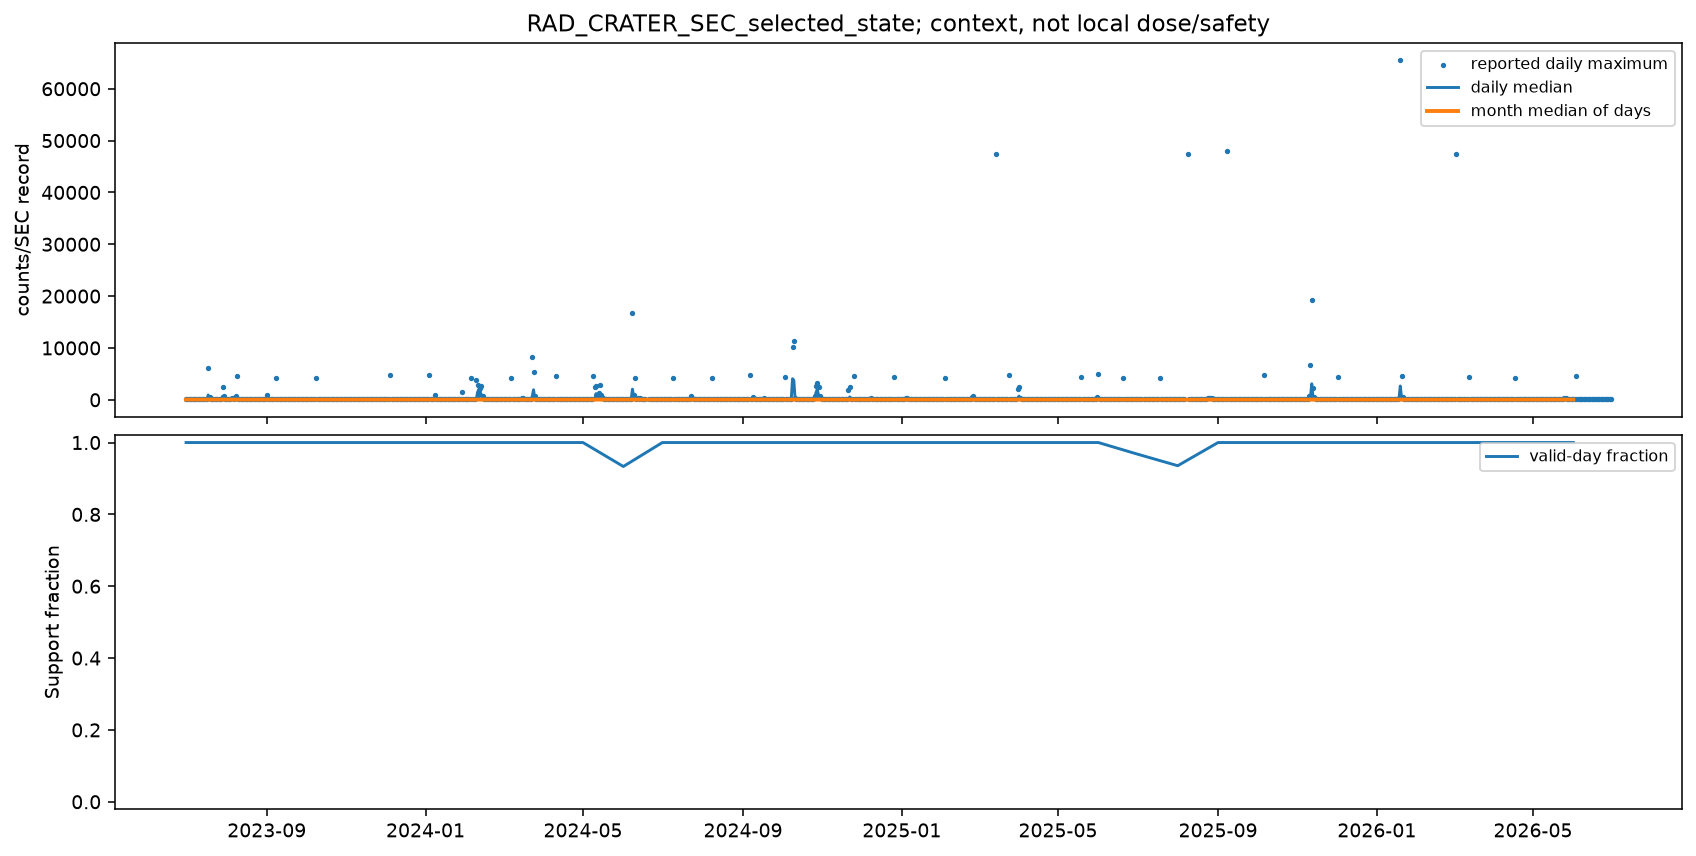

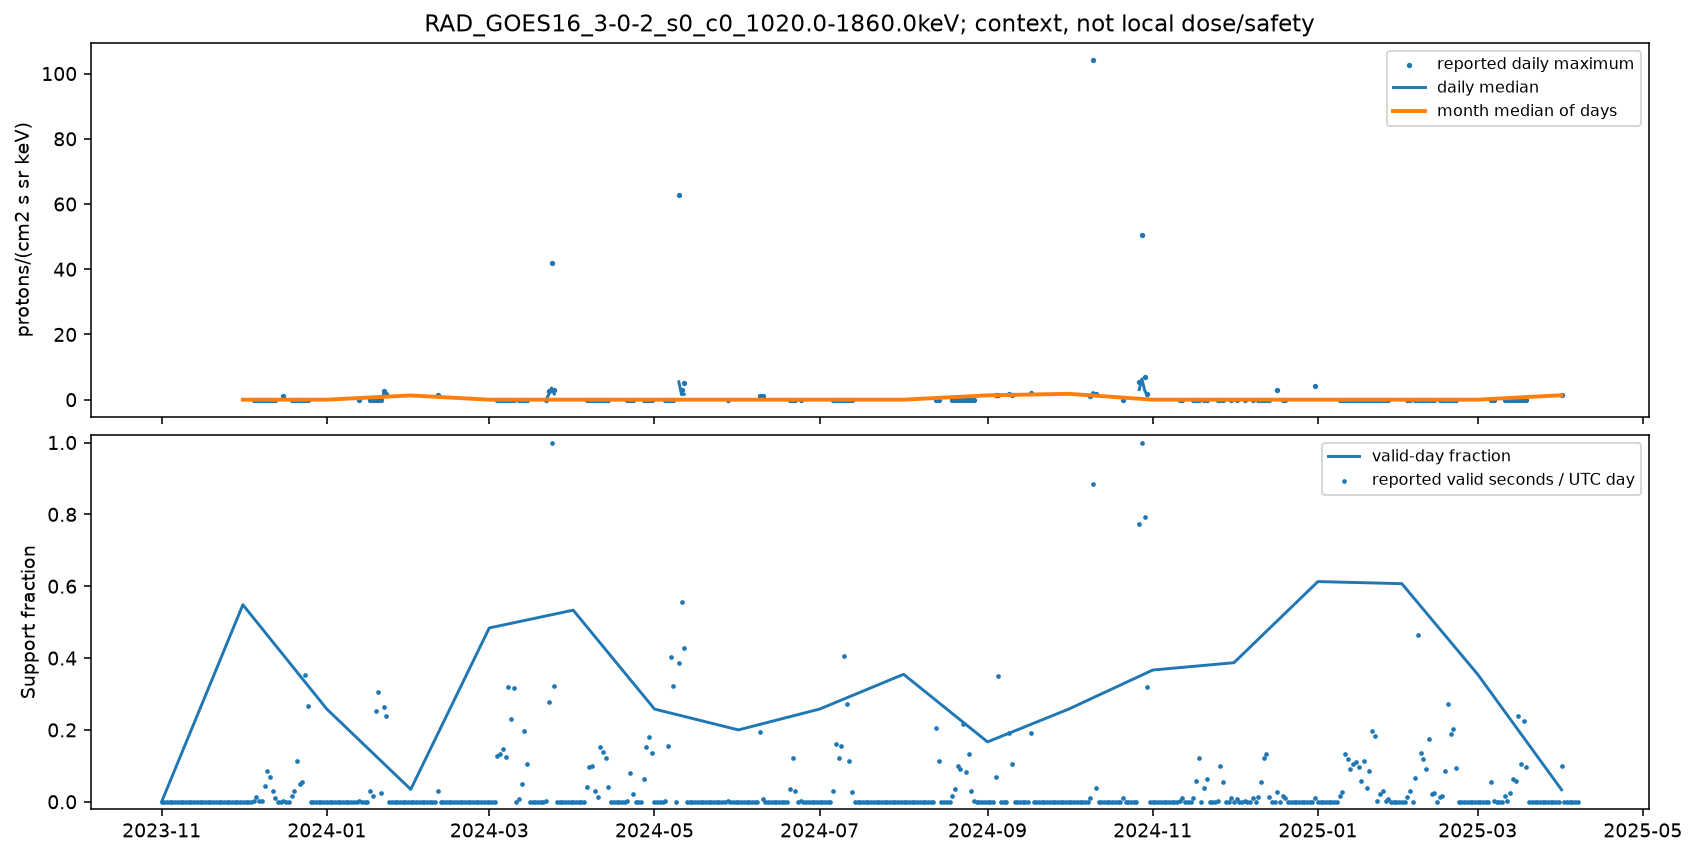

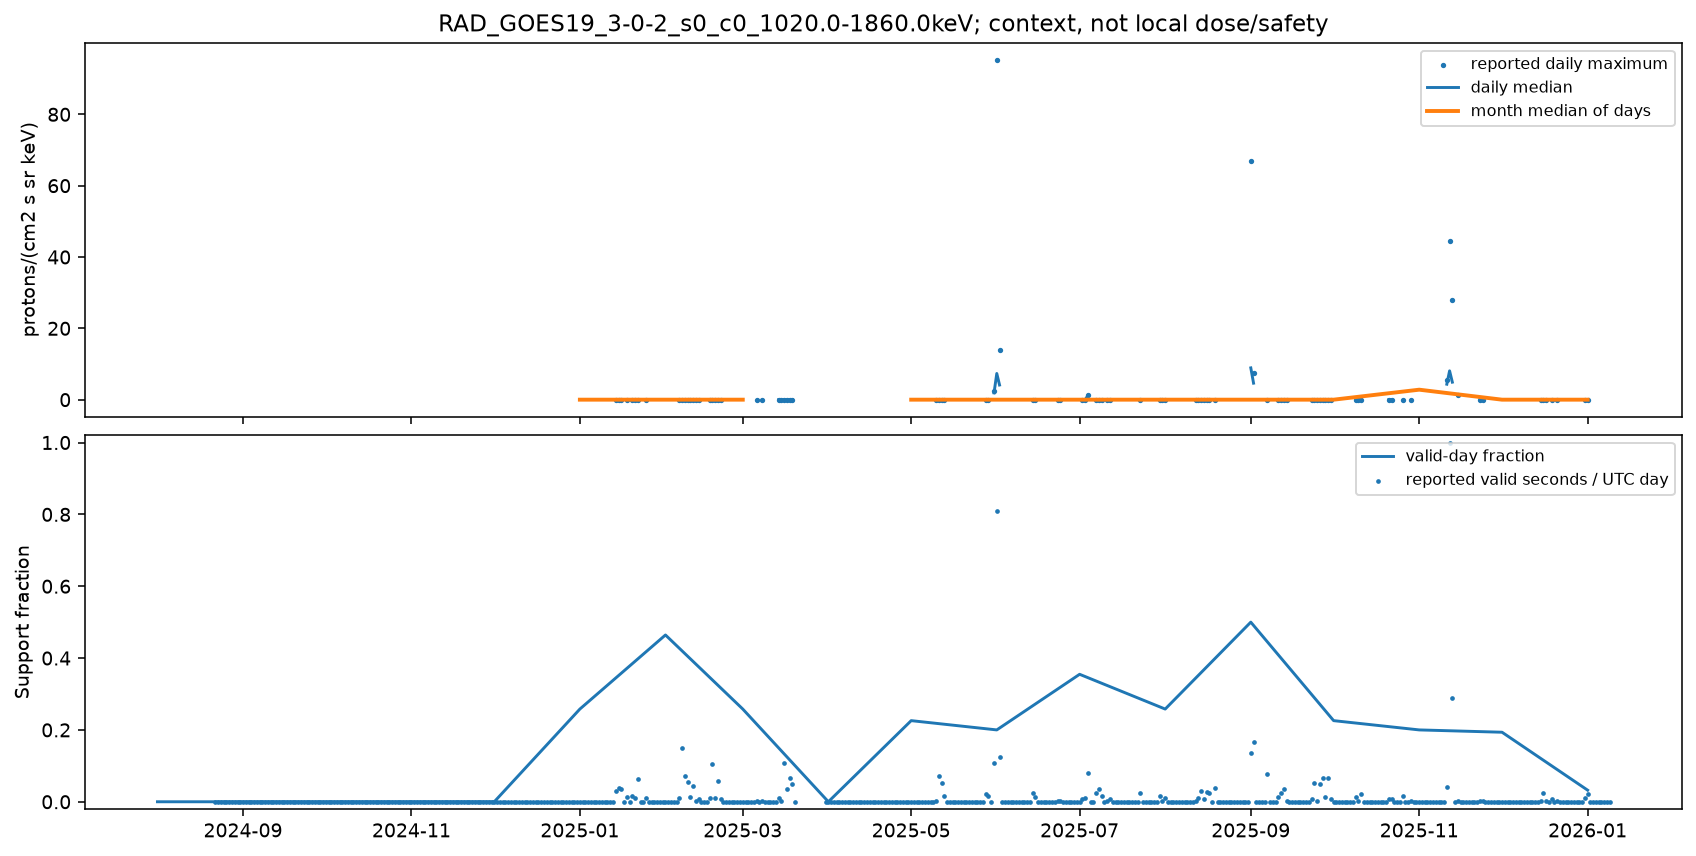

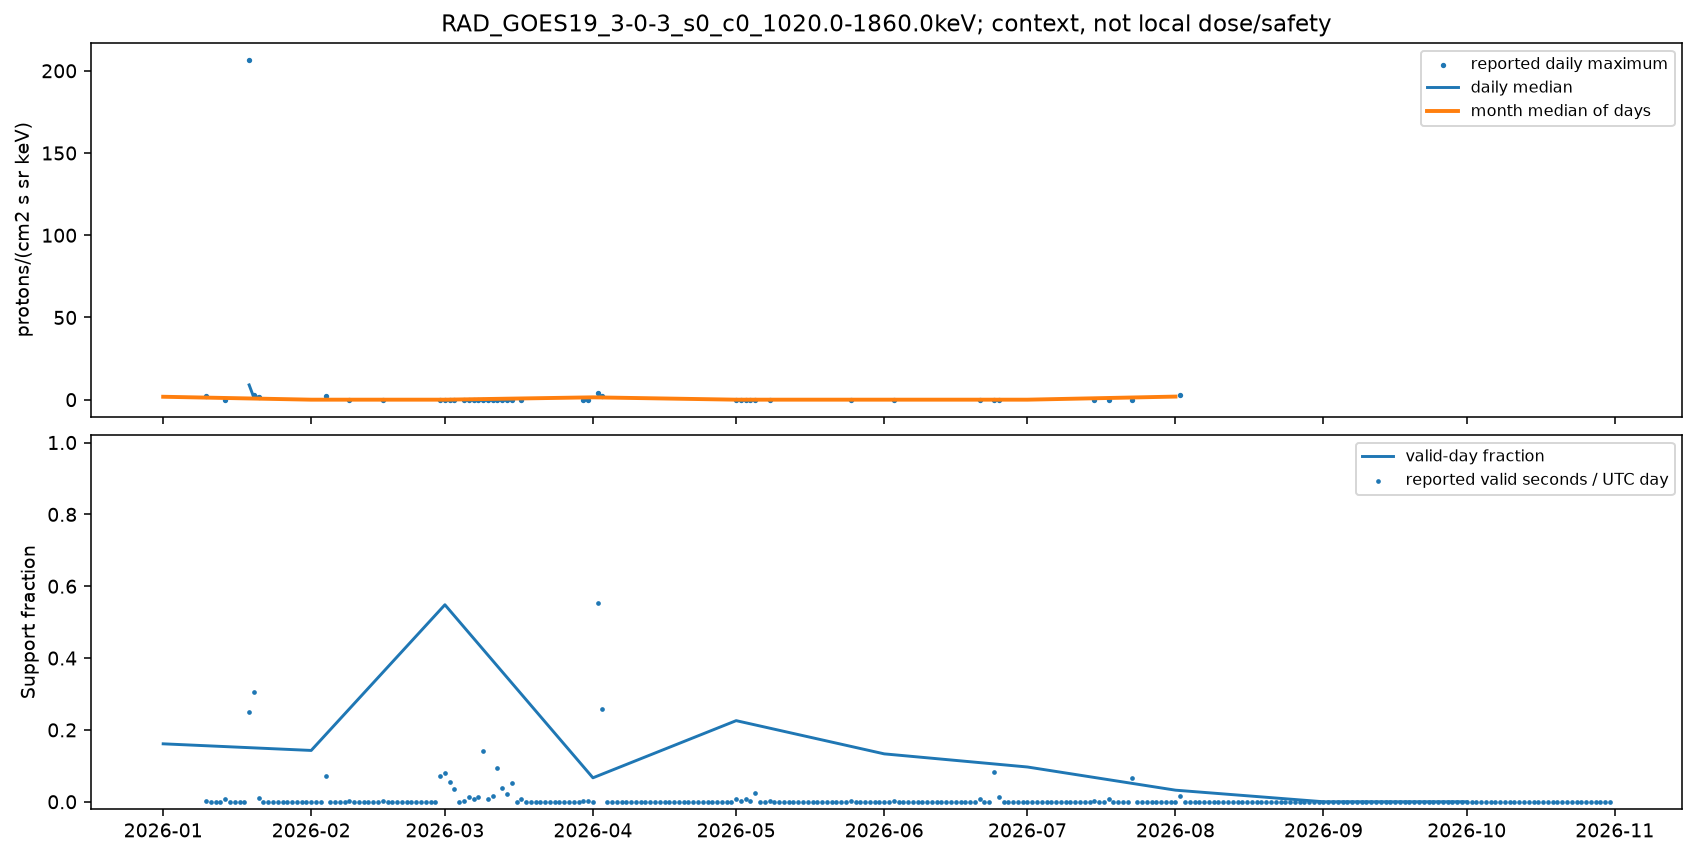

In [3]:
display(pd.read_csv(folder/'calendar_context.csv').groupby('period_kind').size().rename('rows'))
for p in sorted(folder.glob('*levels_support.png')): display(Image(filename=str(p)))

## Descriptive upper-tail segments
The pooled 95th percentile of a series' observed daily maxima is a **sample tag, not a safety limit**. Strictly greater values are tagged. Missing/unsupported dates split segments. Segment counts and consecutive dates are not independent SEP counts, event duration, frequency or hazard rates.

In [4]:
display(pd.read_csv(folder/'descriptive_upper_tail_thresholds.csv'))
display(pd.read_csv(folder/'observed_upper_tail_segments.csv').head(30))

,series_id,quantile,sample_daily_max_quantile,valid_daily_max_dates,strictly_above_dates,threshold_role
0,RAD_CRATER_SEC_selected_state,0.95,2175.000000,1091,55,"sample distribution tag, NOT a physical hazard..."
1,RAD_GOES16_3-0-2_s0_c0_1020.0-1860.0keV,0.95,3.000941,174,9,"sample distribution tag, NOT a physical hazard..."
2,RAD_GOES16_3-0-2_s0_c10_115000.0-143000.0keV,0.95,0.000000,480,0,"sample distribution tag, NOT a physical hazard..."
3,RAD_GOES16_3-0-2_s0_c11_160000.0-242000.0keV,0.95,0.000000,390,0,"sample distribution tag, NOT a physical hazard..."
4,RAD_GOES16_3-0-2_s0_c12_276000.0-404000.0keV,0.95,0.000000,494,0,"sample distribution tag, NOT a physical hazard..."
...,...,...,...,...,...,...
74,RAD_GOES19_3-0-3_s1_c5_11640.0-23270.0keV,0.95,0.000000,178,1,"sample distribution tag, NOT a physical hazard..."
75,RAD_GOES19_3-0-3_s1_c6_25900.0-35200.0keV,0.95,0.000000,187,1,"sample distribution tag, NOT a physical hazard..."
76,RAD_GOES19_3-0-3_s1_c7_41000.0-74000.0keV,0.95,0.000000,193,1,"sample distribution tag, NOT a physical hazard..."
77,RAD_GOES19_3-0-3_s1_c8_78000.0-99700.0keV,0.95,0.000000,192,0,"sample distribution tag, NOT a physical hazard..."


,series_id,start_utc_day,last_observed_utc_day,consecutive_high_summary_dates,maximum_reported_daily_max,sample_daily_max_quantile,first_selected_date_in_source,last_selected_date_in_source,interpretation
0,RAD_CRATER_SEC_selected_state,2023-07-18 00:00:00+00:00,2023-07-18 00:00:00+00:00,1,6195.0,2175.0,False,False,consecutive observed high daily summaries; mis...
1,RAD_CRATER_SEC_selected_state,2023-07-29 00:00:00+00:00,2023-07-29 00:00:00+00:00,1,2552.0,2175.0,False,False,consecutive observed high daily summaries; mis...
2,RAD_CRATER_SEC_selected_state,2023-08-09 00:00:00+00:00,2023-08-09 00:00:00+00:00,1,4493.0,2175.0,False,False,consecutive observed high daily summaries; mis...
3,RAD_CRATER_SEC_selected_state,2023-09-08 00:00:00+00:00,2023-09-08 00:00:00+00:00,1,4196.0,2175.0,False,False,consecutive observed high daily summaries; mis...
4,RAD_CRATER_SEC_selected_state,2023-10-09 00:00:00+00:00,2023-10-09 00:00:00+00:00,1,4225.0,2175.0,False,False,consecutive observed high daily summaries; mis...
5,RAD_CRATER_SEC_selected_state,2023-12-05 00:00:00+00:00,2023-12-05 00:00:00+00:00,1,4766.0,2175.0,False,False,consecutive observed high daily summaries; mis...
6,RAD_CRATER_SEC_selected_state,2024-01-04 00:00:00+00:00,2024-01-04 00:00:00+00:00,1,4746.0,2175.0,False,False,consecutive observed high daily summaries; mis...
7,RAD_CRATER_SEC_selected_state,2024-02-05 00:00:00+00:00,2024-02-05 00:00:00+00:00,1,4256.0,2175.0,False,False,consecutive observed high daily summaries; mis...
8,RAD_CRATER_SEC_selected_state,2024-02-09 00:00:00+00:00,2024-02-10 00:00:00+00:00,2,3806.0,2175.0,False,False,consecutive observed high daily summaries; mis...
9,RAD_CRATER_SEC_selected_state,2024-02-12 00:00:00+00:00,2024-02-13 00:00:00+00:00,2,2573.0,2175.0,False,False,consecutive observed high daily summaries; mis...


## Solar covariation and common-time trends
Contemporary SEE FUV is matched on actual valid UTC dates. Compare pooled level association, within-year association and consecutive-day differences. Correlations with fewer than 30 pairs or constant inputs remain Unknown. No causal, significance, transport or dose model follows.

In [5]:
a=pd.read_csv(folder/'solar_associations.csv')
display(a[a.series_id.eq('RAD_CRATER_SEC_selected_state')])
display(pd.read_csv(folder/'crosscheck_Dar043.csv').agg({'absolute_difference':'max','support_changed':'sum'}))

,series_id,comparison_window,paired_valid_dates,spearman_daily_levels,consecutive_daily_difference_pairs,spearman_daily_first_differences,interpretation
0,RAD_CRATER_SEC_selected_state,all_common_dates,1050,0.464371,1038,-0.001081,descriptive levels/year strata/consecutive-day...
1,RAD_CRATER_SEC_selected_state,2023,183,0.333269,181,-0.039365,descriptive levels/year strata/consecutive-day...
2,RAD_CRATER_SEC_selected_state,2024,349,0.062196,345,-0.015814,descriptive levels/year strata/consecutive-day...
3,RAD_CRATER_SEC_selected_state,2025,351,-0.010234,345,-0.011001,descriptive levels/year strata/consecutive-day...
4,RAD_CRATER_SEC_selected_state,2026,167,-0.151673,165,0.115737,descriptive levels/year strata/consecutive-day...


absolute_difference    2.220446e-16
support_changed        0.000000e+00
dtype: float64

## Stage 4 proposals and base conclusion
Severe applicable radiation must be a mandatory constraint, not traded against sunlight preferences. This data does not establish the applicable local demand or limits: those remain Unknown. Proposed guards/conditional constraints stay separate from the active pipeline.

In [6]:
display(pd.read_csv(folder/'stage4_radiation_proposals.csv')[['id','classification','title','current_outcome','decision_logic']])
print(json.dumps(findings,indent=2))
print('Completed run:',folder)

,id,classification,title,current_outcome,decision_logic
0,RA-G01,evidence_guard,"Preserve radiation quantity, detector and orbit",Unknown,GOES is Earth-orbit space-weather context; LRO...
1,RA-G02,evidence_guard,Upper-tail tags are not detected hazardous events,Unknown,Daily quantile segments describe observed summ...
2,RA-H01,conditional_hard_constraint,Applicable crew/equipment radiation envelope,Unknown,Failed if qualified applicable demand exceeds ...
3,RA-S01,conditional_soft_preference,Lower qualified radiation-protection burden,Unknown,"Prefer supported operational burden, not raw m..."
4,RA-G03,evidence_guard,Calendar/solar associations are descriptive,Unknown,Compare levels with within-year and consecutiv...


{
  "subject": "radiation",
  "sample": false,
  "series": 79,
  "daily_rows": 35281,
  "first_utc": "2023-07-01 00:00:00+00:00",
  "last_utc": "2026-10-31 00:00:00+00:00",
  "tables": {
    "daily_context": 35281,
    "series_catalog": 79,
    "calendar_context": 3152,
    "matched_June_October_years": 108,
    "descriptive_upper_tail_thresholds": 79,
    "observed_upper_tail_segments": 138,
    "solar_associations": 212,
    "paired_solar_daily_values": 19459,
    "previous_monthly_context": 1232,
    "stage4_radiation_proposals": 5,
    "crosscheck_Dar043": 1232
  },
  "crater_solar_descriptive_checks": [
    {
      "series_id": "RAD_CRATER_SEC_selected_state",
      "comparison_window": "all_common_dates",
      "paired_valid_dates": 1050,
      "spearman_daily_levels": 0.4643706292589558,
      "consecutive_daily_difference_pairs": 1038,
      "spearman_daily_first_differences": -0.0010812646766402746,
      "interpretation": "descriptive levels/year strata/consecutive-day differ